In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.spatial.transform import Rotation
from scipy.stats import pearsonr

CSV_PATH = "/home/pooja/TATRO/TATRO_Program_files/TATARO_FirmwareV1.0/xarm_ros2/MOCAP_Validation/marker_charuco_tf_log_20260717_153058.csv"

# Column mapping from marker_charuco_tf_logger.py onto the four transforms
# this analysis is defined over:
#   T_base_eef      -> EEF_*          (link_base -> link_eef, robot FK)
#   T_base_camera   -> Camera_*       (link_base -> camera_color_optical_frame,
#                                       FK + published hand-eye calibration)
#   T_base_charuco  -> CharucoBase_*  (link_base -> charuco_board_frame,
#                                       full chain: FK + calibration + detection)
#   T_camera_charuco -> CharucoCam_*  (camera_color_optical_frame -> charuco_board_frame,
#                                       raw detection only)
#
# Uses every sample in the log where the three transforms this analysis
# needs (EEF, Camera, CharucoBase) resolved - not just the User_Marker==1
# events - since the point here is per-sample correlation power, and
# restricting to the ~200 marked/averaged samples throws away the vast
# majority of the data for no benefit (the marker is fixed regardless of
# whether a given instant happened to be flagged with 'S').
df = pd.read_csv(CSV_PATH)
df["Timestamp"] = pd.to_datetime(df["Timestamp"], format="%Y-%m-%d %H:%M:%S.%f")
valid = df[(df.EEF_Valid == 1) & (df.Camera_Valid == 1) & (df.CharucoBase_Valid == 1)].reset_index(drop=True)

print(f"Valid samples: {len(valid)} / {len(df)}")
valid.head()

Valid samples: 4062 / 4441


,Timestamp,User_Marker,EEF_Valid,EEF_X,EEF_Y,EEF_Z,EEF_QX,EEF_QY,EEF_QZ,EEF_QW,...,CharucoBase_QZ,CharucoBase_QW,CharucoCam_Valid,CharucoCam_X,CharucoCam_Y,CharucoCam_Z,CharucoCam_QX,CharucoCam_QY,CharucoCam_QZ,CharucoCam_QW
0,2026-07-17 15:30:58.963,0,1,0.151222,-0.000918,0.431966,0.907901,0.001874,0.419015,0.011783,...,-0.060045,0.058817,1,0.124515,-0.049455,0.686592,-0.254806,0.277072,0.651368,0.658805
1,2026-07-17 15:30:59.024,0,1,0.151222,-0.000918,0.431966,0.907901,0.001874,0.419015,0.011783,...,-0.060045,0.058817,1,0.124515,-0.049455,0.686592,-0.254806,0.277072,0.651368,0.658805
2,2026-07-17 15:30:59.058,0,1,0.151222,-0.000918,0.431966,0.907901,0.001874,0.419015,0.011783,...,-0.052889,0.067074,1,0.124174,-0.050222,0.691863,-0.255525,0.265057,0.651899,0.662933
3,2026-07-17 15:30:59.091,0,1,0.151222,-0.000918,0.431966,0.907901,0.001874,0.419015,0.011783,...,-0.056812,0.072632,1,0.124878,-0.051947,0.698779,-0.243428,0.262230,0.651075,0.669387
4,2026-07-17 15:30:59.124,0,1,0.151222,-0.000918,0.431966,0.907901,0.001874,0.419015,0.011783,...,-0.055681,0.070862,1,0.124537,-0.050603,0.693030,-0.251293,0.264297,0.651806,0.664942


In [20]:
# 1. Mean ChArUco pose in the robot base frame (T_base_charuco).
# Position: plain mean. Orientation: chordal-L2 mean (Markley's method, via
# scipy's Rotation.mean()) rather than averaging quaternion components
# directly, which is not a valid rotation average.
charuco_pos = valid[["CharucoBase_X", "CharucoBase_Y", "CharucoBase_Z"]].to_numpy()
charuco_quat = valid[["CharucoBase_QX", "CharucoBase_QY", "CharucoBase_QZ", "CharucoBase_QW"]].to_numpy()

mean_charuco_pos = charuco_pos.mean(axis=0)
mean_charuco_rot = Rotation.from_quat(charuco_quat).mean()

print(f"Mean ChArUco position (mm): ({mean_charuco_pos[0]*1000:.2f}, {mean_charuco_pos[1]*1000:.2f}, {mean_charuco_pos[2]*1000:.2f})")
print(f"Mean ChArUco orientation (roll, pitch, yaw, deg): {mean_charuco_rot.as_euler('xyz', degrees=True).round(2)}")

Mean ChArUco position (mm): (742.60, -69.93, 29.63)
Mean ChArUco orientation (roll, pitch, yaw, deg): [-176.79    2.47 -175.35]


In [21]:
# 2. Per-sample ChArUco position error relative to the mean.
error = charuco_pos - mean_charuco_pos
valid["error_x"] = error[:, 0]
valid["error_y"] = error[:, 1]
valid["error_z"] = error[:, 2]
valid["error_norm"] = np.linalg.norm(error, axis=1)

error_mm = error * 1000
error_norm_mm = valid["error_norm"].to_numpy() * 1000

valid[["error_x", "error_y", "error_z", "error_norm"]].describe()

,error_x,error_y,error_z,error_norm
count,4.062000e+03,4.062000e+03,4.062000e+03,4062.000000
mean,-4.722958e-17,1.661781e-17,3.498487e-18,0.048431
std,2.308542e-02,2.692966e-02,3.784786e-02,0.018561
min,-9.872563e-02,-4.470734e-02,-6.651199e-02,0.008088
25%,-2.078363e-02,-2.743310e-02,-2.478049e-02,0.036413
50%,-6.498296e-03,1.332381e-02,-1.413617e-02,0.045677
75%,2.453910e-02,2.557659e-02,4.272738e-02,0.065266
max,4.558053e-02,5.068488e-02,1.460761e-01,0.170139


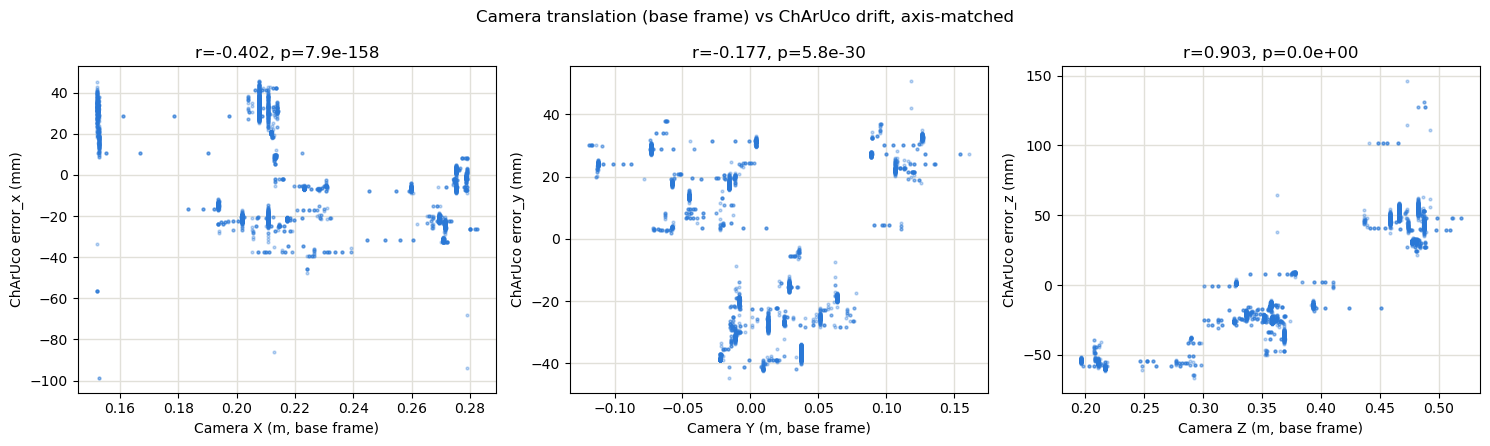

In [22]:
# 3. Camera translation vs ChArUco drift, axis-matched.
cam_pos = valid[["Camera_X", "Camera_Y", "Camera_Z"]].to_numpy()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for i, (ax_name, err_col) in enumerate(zip("XYZ", ["error_x", "error_y", "error_z"])):
    r, p = pearsonr(cam_pos[:, i], valid[err_col].to_numpy())
    axes[i].scatter(cam_pos[:, i], valid[err_col].to_numpy() * 1000, s=4, alpha=0.3, color="#2a78d6")
    axes[i].set_xlabel(f"Camera {ax_name} (m, base frame)")
    axes[i].set_ylabel(f"ChArUco error_{ax_name.lower()} (mm)")
    axes[i].set_title(f"r={r:.3f}, p={p:.1e}")
    axes[i].grid(color="#e1e0d9", linewidth=1)
    axes[i].set_axisbelow(True)
fig.suptitle("Camera translation (base frame) vs ChArUco drift, axis-matched")
plt.tight_layout()
plt.show()

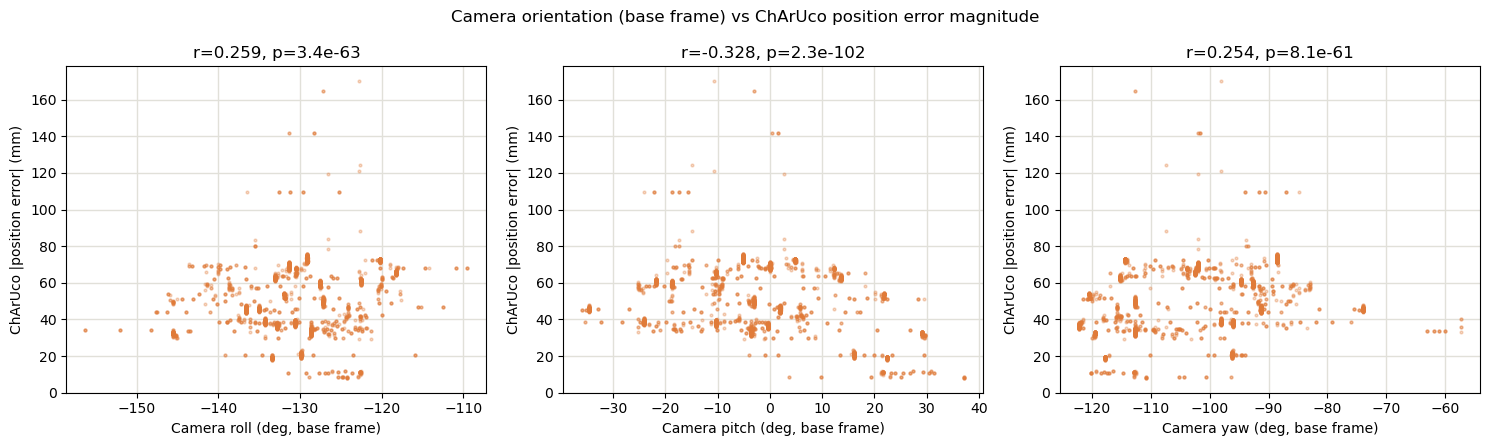

In [23]:
# 4. Camera orientation (roll/pitch/yaw, deg) vs ChArUco position error magnitude.
cam_quat = valid[["Camera_QX", "Camera_QY", "Camera_QZ", "Camera_QW"]].to_numpy()
cam_euler_deg = Rotation.from_quat(cam_quat).as_euler("xyz", degrees=True)
valid["Camera_roll_deg"] = cam_euler_deg[:, 0]
valid["Camera_pitch_deg"] = cam_euler_deg[:, 1]
valid["Camera_yaw_deg"] = cam_euler_deg[:, 2]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for i, name in enumerate(["roll", "pitch", "yaw"]):
    col = f"Camera_{name}_deg"
    r, p = pearsonr(valid[col].to_numpy(), error_norm_mm)
    axes[i].scatter(valid[col].to_numpy(), error_norm_mm, s=4, alpha=0.3, color="#e07b39")
    axes[i].set_xlabel(f"Camera {name} (deg, base frame)")
    axes[i].set_ylabel("ChArUco |position error| (mm)")
    axes[i].set_title(f"r={r:.3f}, p={p:.1e}")
    axes[i].grid(color="#e1e0d9", linewidth=1)
    axes[i].set_axisbelow(True)
fig.suptitle("Camera orientation (base frame) vs ChArUco position error magnitude")
plt.tight_layout()
plt.show()

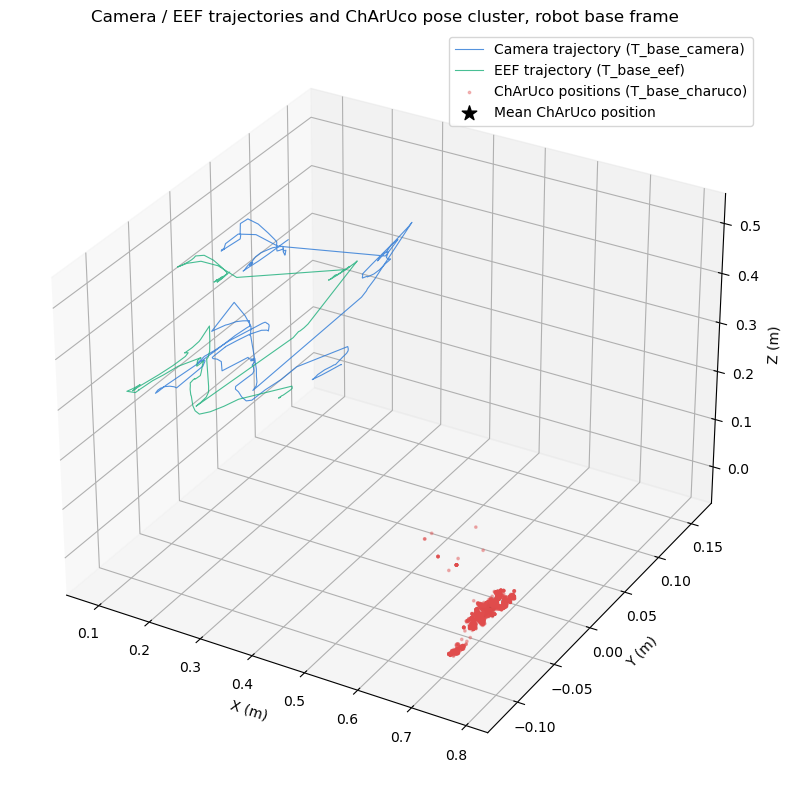

In [24]:
# 5. 3D visualization: camera trajectory, EEF trajectory, and all ChArUco positions.
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

ax.plot(valid["Camera_X"].to_numpy(), valid["Camera_Y"].to_numpy(), valid["Camera_Z"].to_numpy(),
        color="#2a78d6", linewidth=0.8, alpha=0.8, label="Camera trajectory (T_base_camera)")
ax.plot(valid["EEF_X"].to_numpy(), valid["EEF_Y"].to_numpy(), valid["EEF_Z"].to_numpy(),
        color="#1baf7a", linewidth=0.8, alpha=0.8, label="EEF trajectory (T_base_eef)")
ax.scatter(valid["CharucoBase_X"].to_numpy(), valid["CharucoBase_Y"].to_numpy(), valid["CharucoBase_Z"].to_numpy(),
           color="#e04c4c", s=3, alpha=0.35, label="ChArUco positions (T_base_charuco)")
ax.scatter(*mean_charuco_pos, color="black", s=120, marker="*", label="Mean ChArUco position")

ax.set_xlabel("X (m)"); ax.set_ylabel("Y (m)"); ax.set_zlabel("Z (m)")
ax.set_title("Camera / EEF trajectories and ChArUco pose cluster, robot base frame")
ax.legend()
plt.tight_layout()
plt.show()

In [25]:
# 6. Summary statistics and correlation coefficients between camera motion and ChArUco drift.
std_mm = charuco_pos.std(axis=0) * 1000
max_drift_mm = error_norm_mm.max()

print("--- ChArUco position summary ---")
print(f"Mean (mm):     ({mean_charuco_pos[0]*1000:.2f}, {mean_charuco_pos[1]*1000:.2f}, {mean_charuco_pos[2]*1000:.2f})")
print(f"Std dev (mm):  ({std_mm[0]:.2f}, {std_mm[1]:.2f}, {std_mm[2]:.2f})")
print(f"RMS drift (mm): {np.sqrt((error_norm_mm**2).mean()):.2f}")
print(f"Max drift (mm): {max_drift_mm:.2f}")

# Axis-matched translation correlations, plus each rotation angle against
# the drift magnitude (there is no natural "matching axis" for rotation the
# way Camera_X matches error_x for translation).
translation_corrs = []
for i, ax_name in enumerate("XYZ"):
    r, p = pearsonr(cam_pos[:, i], error[:, i])
    translation_corrs.append({"quantity": f"Camera_{ax_name} vs error_{ax_name.lower()}", "r": r, "p_value": p})

rotation_corrs = []
for name in ["roll", "pitch", "yaw"]:
    r, p = pearsonr(valid[f"Camera_{name}_deg"].to_numpy(), error_norm_mm)
    rotation_corrs.append({"quantity": f"Camera_{name} vs |error|", "r": r, "p_value": p})

correlation_df = pd.DataFrame(translation_corrs + rotation_corrs)
correlation_df["abs_r"] = correlation_df["r"].abs()
correlation_df = correlation_df.sort_values("abs_r", ascending=False).drop(columns="abs_r").reset_index(drop=True)
correlation_df

--- ChArUco position summary ---
Mean (mm):     (742.60, -69.93, 29.63)
Std dev (mm):  (23.08, 26.93, 37.84)
RMS drift (mm): 51.86
Max drift (mm): 170.14


,quantity,r,p_value
0,Camera_Z vs error_z,0.902785,0.000000e+00
1,Camera_X vs error_x,-0.402235,7.864148e-158
2,Camera_pitch vs |error|,-0.327808,2.276976e-102
3,Camera_roll vs |error|,0.258879,3.354092e-63
4,Camera_yaw vs |error|,0.253972,8.105624e-61
5,Camera_Y vs error_y,-0.177068,5.785097e-30


In [26]:
# --- Interpretation --------------------------------------------------------
translation_r = [row["r"] for row in translation_corrs]
rotation_r = [row["r"] for row in rotation_corrs]
max_abs_translation_r = max(abs(r) for r in translation_r)
max_abs_rotation_r = max(abs(r) for r in rotation_r)

TIGHT_CLUSTER_THRESHOLD_MM = 5.0     # a well-calibrated system should stay within a few mm
STRONG_CORR_THRESHOLD = 0.5          # |r| above this is a meaningful, not just statistically-significant, effect

rms_drift_mm = np.sqrt((error_norm_mm**2).mean())
print(f"RMS drift: {rms_drift_mm:.1f} mm, max drift: {max_drift_mm:.1f} mm")
if rms_drift_mm < TIGHT_CLUSTER_THRESHOLD_MM:
    print("-> Tight cluster: consistent with an accurate calibration.")
else:
    print("-> NOT a tight cluster: the calibration has a real, non-trivial error.")

print()
best_translation = translation_corrs[np.argmax([abs(r) for r in translation_r])]
best_rotation = rotation_corrs[np.argmax([abs(r) for r in rotation_r])]
print(f"Strongest translation correlation:  |r| = {max_abs_translation_r:.3f} ({best_translation['quantity']})")
print(f"Strongest rotation correlation:     |r| = {max_abs_rotation_r:.3f} ({best_rotation['quantity']})")

if max_abs_translation_r > STRONG_CORR_THRESHOLD:
    print("-> Drift increases with camera translation: the TRANSLATION component")
    print("   of the hand-eye calibration (eef_T_cam) is the more likely source of error.")
if max_abs_rotation_r > STRONG_CORR_THRESHOLD:
    print("-> Drift also correlates with camera rotation: the ROTATION component")
    print("   of the calibration may be contributing too.")

print()
if max_abs_translation_r > max_abs_rotation_r:
    print(f"Verdict: marker drift is MORE SENSITIVE TO CAMERA POSITION "
          f"({max_abs_translation_r:.3f} vs {max_abs_rotation_r:.3f}).")
    print("This points at the calibration's translation offset (or a depth/scale")
    print("error along the correlated axis) rather than its rotation matrix.")
else:
    print(f"Verdict: marker drift is MORE SENSITIVE TO CAMERA ORIENTATION "
          f"({max_abs_rotation_r:.3f} vs {max_abs_translation_r:.3f}).")
    print("This points at the calibration's rotation matrix as the dominant error source.")

RMS drift: 51.9 mm, max drift: 170.1 mm
-> NOT a tight cluster: the calibration has a real, non-trivial error.

Strongest translation correlation:  |r| = 0.903 (Camera_Z vs error_z)
Strongest rotation correlation:     |r| = 0.328 (Camera_pitch vs |error|)
-> Drift increases with camera translation: the TRANSLATION component
   of the hand-eye calibration (eef_T_cam) is the more likely source of error.

Verdict: marker drift is MORE SENSITIVE TO CAMERA POSITION (0.903 vs 0.328).
This points at the calibration's translation offset (or a depth/scale
error along the correlated axis) rather than its rotation matrix.


Samples with all four chains valid: 4062 / 4441


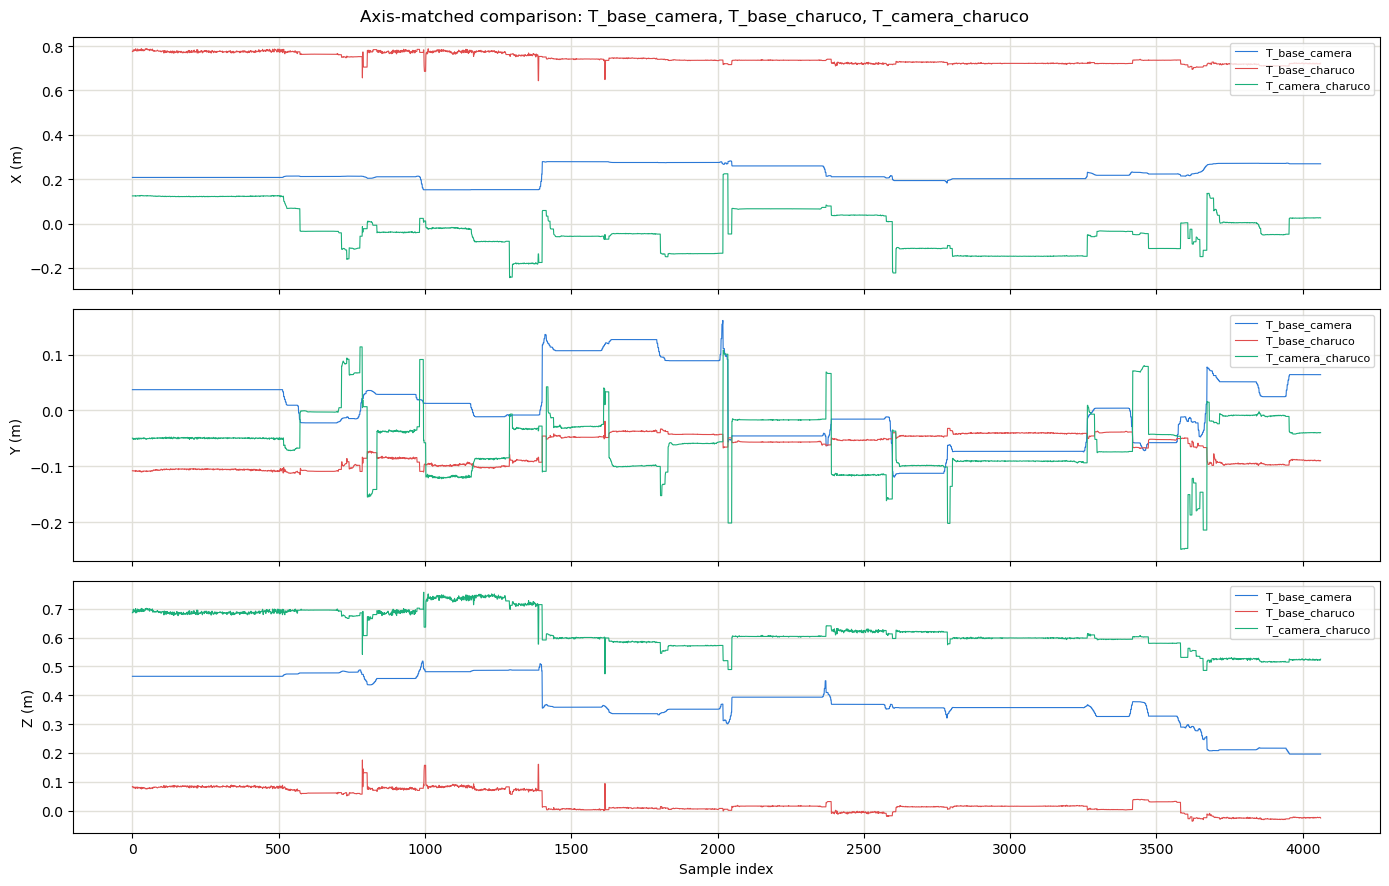

In [27]:
# 7. Axis-matched comparison: T_base_camera, T_base_charuco, T_camera_charuco.
#
# T_base_charuco = T_base_camera (.) T_camera_charuco by construction (TF
# composition), so this is not testing that identity - it is a visual check
# of WHICH of the two inputs the composed result actually tracks. If the
# calibration/robot chain (T_base_camera) is the error source, T_base_charuco
# should visibly echo T_base_camera's motion even though the physical board
# never moves. If it were instead just detection noise, T_base_charuco should
# track T_camera_charuco's noise pattern and be roughly independent of
# T_base_camera.
#
# Requires CharucoCam_Valid too (T_camera_charuco), on top of the EEF/Camera/
# CharucoBase filter already used for 'valid' above.
valid_all = df[(df.EEF_Valid == 1) & (df.Camera_Valid == 1)
               & (df.CharucoBase_Valid == 1) & (df.CharucoCam_Valid == 1)].reset_index(drop=True)
print(f"Samples with all four chains valid: {len(valid_all)} / {len(df)}")

fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
x = np.arange(len(valid_all))
for i, ax_name in enumerate("XYZ"):
    axes[i].plot(x, valid_all[f"Camera_{ax_name}"].to_numpy(), color="#2a78d6", linewidth=0.8, label="T_base_camera")
    axes[i].plot(x, valid_all[f"CharucoBase_{ax_name}"].to_numpy(), color="#e04c4c", linewidth=0.8, label="T_base_charuco")
    axes[i].plot(x, valid_all[f"CharucoCam_{ax_name}"].to_numpy(), color="#1baf7a", linewidth=0.8, label="T_camera_charuco")
    axes[i].set_ylabel(f"{ax_name} (m)")
    axes[i].grid(color="#e1e0d9", linewidth=1)
    axes[i].set_axisbelow(True)
    axes[i].legend(fontsize=8, loc="upper right")
axes[-1].set_xlabel("Sample index")
fig.suptitle("Axis-matched comparison: T_base_camera, T_base_charuco, T_camera_charuco")
plt.tight_layout()
plt.show()

In [28]:
# Quantify what the plot above shows: per axis, does T_base_charuco
# correlate more with T_base_camera (calibration/robot-driven) or with
# T_camera_charuco (detection-noise-driven)?
rows = []
for ax_name in "XYZ":
    cb = valid_all[f"CharucoBase_{ax_name}"].to_numpy()
    cam = valid_all[f"Camera_{ax_name}"].to_numpy()
    cc = valid_all[f"CharucoCam_{ax_name}"].to_numpy()
    r_cam, p_cam = pearsonr(cam, cb)
    r_cc, p_cc = pearsonr(cc, cb)
    rows.append({
        "axis": ax_name,
        "r(T_base_charuco, T_base_camera)": r_cam,
        "r(T_base_charuco, T_camera_charuco)": r_cc,
        "more_driven_by": "camera/calibration" if abs(r_cam) > abs(r_cc) else "detection noise",
    })
axis_driver_df = pd.DataFrame(rows)
axis_driver_df

,axis,"r(T_base_charuco, T_base_camera)","r(T_base_charuco, T_camera_charuco)",more_driven_by
0,X,-0.402235,0.381515,camera/calibration
1,Y,-0.177068,-0.333350,detection noise
2,Z,0.902785,0.888030,camera/calibration


In [29]:
# Rebuild the per-event (per static pose) averages, same approach as
# TransformationValidation02.ipynb: group consecutive User_Marker == 1 rows
# into events, then take the mean position + chordal-L2 mean orientation
# (Rotation.mean()) within each event, per chain.
marker_idx = np.flatnonzero((df["User_Marker"] == 1).to_numpy())
event_groups = []
run = [marker_idx[0]]
for i in marker_idx[1:]:
    if i == run[-1] + 1:
        run.append(i)
    else:
        event_groups.append(run)
        run = [i]
event_groups.append(run)

event_id_col = pd.Series(-1, index=df.index, dtype=int)
for eid, idx in enumerate(event_groups):
    event_id_col.loc[idx] = eid
df["event_id"] = event_id_col

def average_pose(sub_df, prefix):
    pos = sub_df[[f"{prefix}_X", f"{prefix}_Y", f"{prefix}_Z"]].to_numpy()
    quat = sub_df[[f"{prefix}_QX", f"{prefix}_QY", f"{prefix}_QZ", f"{prefix}_QW"]].to_numpy()
    return pos.mean(axis=0), Rotation.from_quat(quat).mean().as_quat()

event_rows = []
for eid, group in df[df["event_id"] >= 0].groupby("event_id"):
    row = {"event_id": eid}
    for prefix in ["EEF", "Camera", "CharucoBase", "CharucoCam"]:
        v = group[group[f"{prefix}_Valid"] == 1]
        pos, quat = average_pose(v, prefix)
        row[f"{prefix}_pos"], row[f"{prefix}_quat"] = pos, quat
    event_rows.append(row)

event_pose_df = pd.DataFrame(event_rows)
print(f"Poses (events): {len(event_pose_df)}")
event_pose_df[["event_id"]]

Poses (events): 18


,event_id
0,0
1,1
2,2
3,3
4,4
5,5
6,6
7,7
8,8
9,9


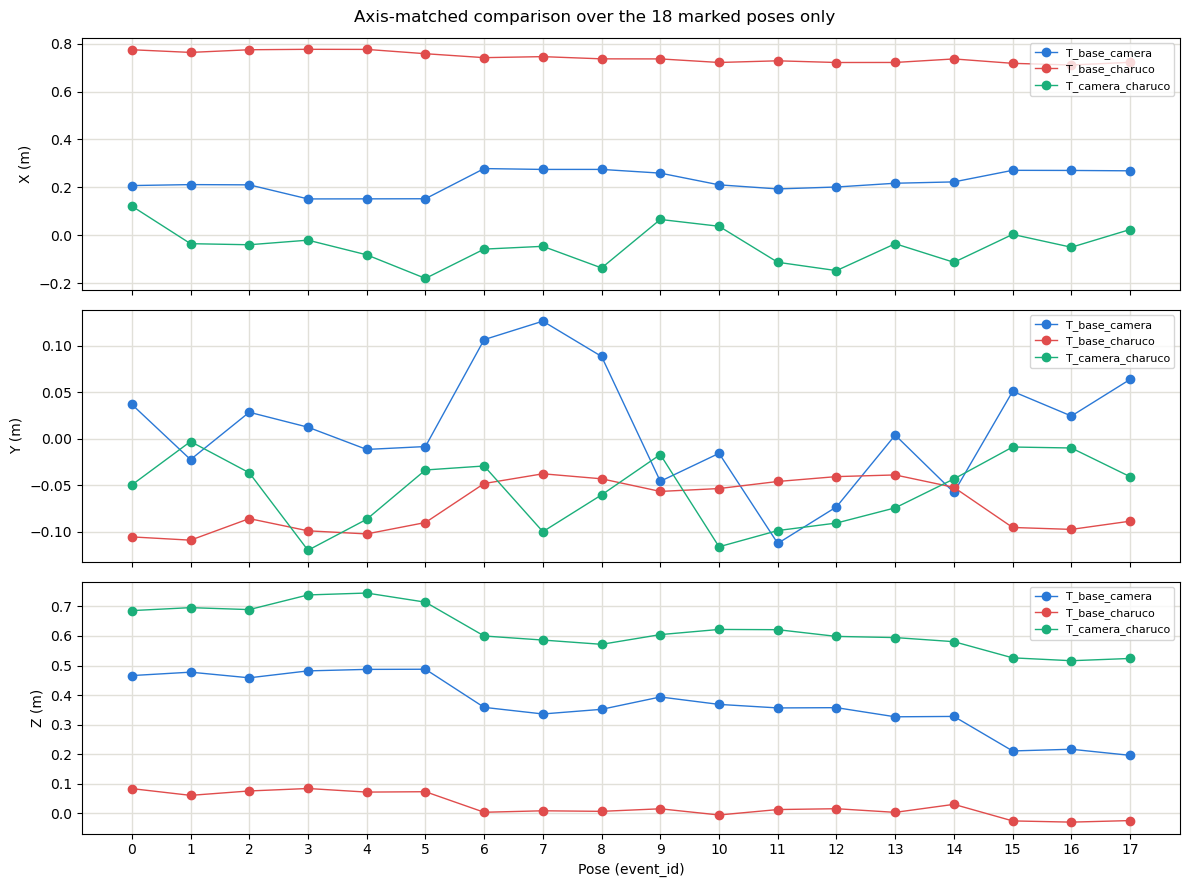

In [30]:
# Axis-matched comparison over the 18 poses only.
cam_pos_18 = np.stack(event_pose_df["Camera_pos"].to_numpy())
cb_pos_18 = np.stack(event_pose_df["CharucoBase_pos"].to_numpy())
cc_pos_18 = np.stack(event_pose_df["CharucoCam_pos"].to_numpy())
x18 = event_pose_df["event_id"].to_numpy()

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for i, ax_name in enumerate("XYZ"):
    axes[i].plot(x18, cam_pos_18[:, i], color="#2a78d6", marker="o", linewidth=1, label="T_base_camera")
    axes[i].plot(x18, cb_pos_18[:, i], color="#e04c4c", marker="o", linewidth=1, label="T_base_charuco")
    axes[i].plot(x18, cc_pos_18[:, i], color="#1baf7a", marker="o", linewidth=1, label="T_camera_charuco")
    axes[i].set_ylabel(f"{ax_name} (m)")
    axes[i].grid(color="#e1e0d9", linewidth=1)
    axes[i].set_axisbelow(True)
    axes[i].legend(fontsize=8, loc="upper right")
axes[-1].set_xlabel("Pose (event_id)")
axes[-1].set_xticks(x18)
fig.suptitle("Axis-matched comparison over the 18 marked poses only")
plt.tight_layout()
plt.show()

In [31]:
# Correlation table for the 18-pose version.
rows18 = []
for i, ax_name in enumerate("XYZ"):
    r_cam, p_cam = pearsonr(cam_pos_18[:, i], cb_pos_18[:, i])
    r_cc, p_cc = pearsonr(cc_pos_18[:, i], cb_pos_18[:, i])
    rows18.append({
        "axis": ax_name,
        "r(T_base_charuco, T_base_camera)": r_cam, "p_camera": p_cam,
        "r(T_base_charuco, T_camera_charuco)": r_cc, "p_charuco_cam": p_cc,
        "more_driven_by": "camera/calibration" if abs(r_cam) > abs(r_cc) else "detection noise",
    })
axis_driver_18_df = pd.DataFrame(rows18)
print(f"n = {len(event_pose_df)} poses")
axis_driver_18_df

n = 18 poses


,axis,"r(T_base_charuco, T_base_camera)",p_camera,"r(T_base_charuco, T_camera_charuco)",p_charuco_cam,more_driven_by
0,X,-0.573870,1.276294e-02,0.075907,7.646684e-01,camera/calibration
1,Y,-0.047157,8.525929e-01,-0.387234,1.123718e-01,detection noise
2,Z,0.926211,3.499549e-08,0.936310,1.113492e-08,detection noise
